# 1 · SAT probability model

I'm starting with the uncertainty in the answers themselves: how many questions might be correct, given different confidence levels and guessing patterns? This notebook contains the model, the reasoning behind it, and a first experiment with converting counts into SAT points.

The examples use synthetic inputs. The answer-count calculation is exact under the assigned probabilities and independence assumptions. The SAT-point conversion is still experimental and hasn't been checked against real scores.

The sensitivity analysis below compares different assumed easier-route caps. Next, I plan to compare confidence probabilities, as described in [my progress notes](../PROGRESS.md).

I use the **SAT Lab (Python)** kernel and run the cells in order.

References: [College Board scoring](https://satsuite.collegeboard.org/scores/what-scores-mean/how-scores-calculated) and the [technical manual](https://research.collegeboard.org/media/pdf/Digital%20SAT%20Suite%20of%20Assessments%20Technical%20Manual-FINAL.pdf).

In [6]:
from pathlib import Path
import sys

# Works when Jupyter starts in the project folder or in notebooks/.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "satlab").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dataclasses import replace
from satlab.model import (Counts, Settings, poisson_binomial, summarize,
                          predict_test, predict_section)
from satlab.examples import example_modules


In [7]:
import numpy as np

rng = np.random.default_rng(42)
answers = rng.binomial(n=1, p=0.5, size=(10))

print("Answers outcomes:", answers)
print("Number Correct:", answers.sum())


Answers outcomes: [1 0 1 1 0 1 1 1 0 0]
Number Correct: 6


p = 0.5 means each guess has a 50% chance of being correct.
A 1 represents a correct answer, and a 0 represents an incorrect anwser. Adding the outcomes gives the number of correct anwsers in a specific section

My simulation produced 6 correct answers out of 10. The expected number of correct answers is 5, but keep in mind that random variation means an individual trial can produce a different result, espeically over a short amount of trails.

THIS IS ONLY FOR GUESSING BETWEEN 2 ANSWERS

In [8]:
personA = [1/2, 1/2, 1/2, 1/2]
personB = [1, 1/4, 1/4, 1/3]

rng = np.random.default_rng(15)
outcomesA = rng.binomial(n=1, p=personA)
print("Person A outcomes:", outcomesA)
print("Their total:", outcomesA.sum())

outcomesB = rng.binomial(n=1, p=personB)
print("Person B outcomes:", outcomesB)
print("Their total:", outcomesB.sum())

rng = np.random.default_rng(16)

winsA = 0
winsB = 0
ties = 0

num_trials = 101
for trial in range(num_trials):
    outcomesA = rng.binomial(n=1, p=personA)
    outcomesB = rng.binomial(n=1, p=personB)


    totalA = outcomesA.sum()
    totalB = outcomesB.sum()

    if totalA > totalB:
        winsA += 1
    elif totalB > totalA:
        winsB += 1
    else:
        ties += 1

print("Person A wins:", winsA)
print("Person B wins:", winsB)
print("Ties:", ties)


print("Person A win proportion:", winsA / num_trials)
print("Person B win proportion:", winsB / num_trials)
print("Tie proportion:", ties / num_trials)

winsA / (winsA + winsB)

from fractions import Fraction
print("Person A win proportion (excluding ties):", Fraction(winsA, winsA + winsB))

Person A outcomes: [1 1 0 0]
Their total: 2
Person B outcomes: [1 0 0 0]
Their total: 1
Person A wins: 43
Person B wins: 28
Ties: 30
Person A win proportion: 0.42574257425742573
Person B win proportion: 0.27722772277227725
Tie proportion: 0.297029702970297
Person A win proportion (excluding ties): 43/71


I wanted to learn how to simulate someone answering questions with different probabilities of being correct, such as 1/4, 1/2, 1, and 1/3. I reused what I wrote for my last commit as a comparison.

For this simulation I compared two people with different probabilities for their answers. Person A had [1/2, 1/2, 1/2, 1/2] and Person B had [1, 1/4, 1/4, 1/3]. Each probability represents the chance of getting that question correct. A 1 represents a correct answer and a 0 represents an incorrect answer. Adding the outcomes gives the total correct for each person.

I used a for loop to compare them over 101 trials. Person A won 43 times, Person B won 28 times, and they tied 30 times. Person A won about 42.6% of all trials, but if we exclude ties, Person A won 43/71, or about 60.6% of the trials with a winner.

Person A’s expected number correct is 2 and Person B’s is about 1.83, but this does not mean Person A will win every time. There is still random variation, even when we repeat the experiment. Also, having a 50% chance of getting each question correct does not mean having a 50% chance of beating the other person.

I kept the random generator outside the loop so it could keep producing new draws. Using the same seed and running the same code again repeats the sequence.

In [9]:
totalsA = []
totalsB = []

for trials in range(num_trials):
    outcomesA = rng.binomial(n=1, p=personA)
    outcomesB = rng.binomial(n=1, p=personB)

    totalsA.append(int(outcomesA.sum()))
    totalsB.append(int(outcomesB.sum()))
print("Person A total outcomes:", totalsA[:10])
print("Person B total outcomes:", totalsB[:10])

rangeA = np.percentile(totalsA, [5, 50, 95], method="inverted_cdf")
rangeB = np.percentile(totalsB, [5, 50, 95], method="inverted_cdf")
print("Person A low, median, high:", rangeA)
print("Person B low, median, high:", rangeB)

insideB = 0

for total in totalsB:
    if rangeB[0] <= total <= rangeB[2]:
        insideB += 1
print("Person B outcomes inside the range:", insideB)

proportionB = insideB / len(totalsB)
print("Person B proportion inside the range:", proportionB)

Person A total outcomes: [0, 1, 4, 2, 4, 2, 1, 3, 1, 2]
Person B total outcomes: [1, 2, 1, 1, 2, 2, 2, 3, 2, 3]
Person A low, median, high: [1 2 4]
Person B low, median, high: [1 2 3]
Person B outcomes inside the range: 100
Person B proportion inside the range: 0.9900990099009901


I wanted to use the simulated correct-answer counts to find a likely low, median, and high result. I created two lists to store each person’s total correct across the trials. Inside the loop, I added each trial’s total to the corresponding list using append. I printed the first 10 totals to check what was being stored.

I used the 5th, 50th, and 95th percentiles to calculate the low, median, and high counts. These cutoffs target the middle 90% of the simulated results. I used the inverted_cdf method so the results would be whole-number counts.

For Person B, I counted how many totals fell between the low and high endpoints, including both endpoints. I reset the counter to 0 before counting, then divided the count by the total number of trials to find the proportion inside the range.

The proportion can be higher than 90% because multiple trials can have the same whole-number total at the endpoints. This range describes likely correct-answer counts under the probabilities I used in the previous cell. It is not a guaranteed minimum or maximum, and it does not convert the counts into SAT scores yet.

In [10]:
half_probs = []

for questions in range(27):
    half_probs.append(1/2)

fourth_probs = []

for questions in range(27):
    fourth_probs.append(1/4)

print(len(half_probs), len(fourth_probs))

rng = np.random.default_rng(17)
num_trials = 101

confidence_levels = [1, 1/2, 1/3, 1/4]
mixed_probs = rng.choice(confidence_levels, size=27)
print("Mixed probabilities:", mixed_probs)

mixed_totals = []
for trials in range(num_trials):
    mixed_outcomes = rng.binomial(n=1, p=mixed_probs)
    mixed_totals.append(int(mixed_outcomes.sum()))
print(len(mixed_totals))

mixed_range = np.percentile(mixed_totals, [5, 50, 95], method="inverted_cdf")
print("Mixed low, median, high:", mixed_range)

inside_mixed = 0

for total in mixed_totals:
    if mixed_range[0] <= total <= mixed_range[2]:
        inside_mixed += 1
print("Total inside the range:", inside_mixed)

proportion_mixed = inside_mixed / len(mixed_totals)
print("Proportion inside the range:", proportion_mixed)

assert len(mixed_probs) == 27
assert len(mixed_totals) == num_trials
assert all(0 <= total <= 27 for total in mixed_totals)
print("All assertions passed.")

27 27
Mixed probabilities: [0.33333333 0.25       1.         1.         0.5        0.33333333
 0.25       0.5        1.         1.         0.5        0.5
 0.25       0.5        0.33333333 0.33333333 1.         0.33333333
 1.         1.         0.33333333 0.5        0.5        0.33333333
 1.         1.         0.33333333]
101
Mixed low, median, high: [13 16 19]
Total inside the range: 94
Proportion inside the range: 0.9306930693069307
All assertions passed.


I wanted to expand the earlier experiment to a full 27-question Reading and Writing module. I randomly assigned each question a confidence probability from [1, 1/2, 1/3, 1/4], then kept that mix fixed while simulating the module 101 times.

For each trial, I generated a correct or incorrect outcome for every question and stored the total correct. I used a fixed seed so rerunning the cell would reproduce both the confidence mix and the sequence of simulated results.

I calculated the 5th, 50th, and 95th percentiles to find the low, median, and high counts. My results were 13, 16, and 19 correct out of 27. The range from 13 to 19 included 94 of the 101 trials, or about 93.1%.

These cutoffs target the middle 90% of the simulated results, but whole-number counts can make the proportion inside the range higher. The endpoints are not guaranteed limits. A future trial could fall outside them.

I also added assertions to check that there were 27 probabilities, one stored total per trial, and no totals outside 0–27. All checks passed. This experiment estimates correct-answer counts using the supplied confidence probabilities; it does not convert them into SAT scores yet.

In [11]:
rng = np.random.default_rng(18)
num_trials = 101
confidence_levels = [1, 1/2, 1/3, 1/4]

module1_probs = rng.choice(confidence_levels, size=27)
module2_probs = rng.choice(confidence_levels, size=27)

section_totals = []

for trial in range(num_trials):

    module1_outcomes = rng.binomial(n=1, p=module1_probs)
    module2_outcomes = rng.binomial(n=1, p=module2_probs)

    total_outcome = module1_outcomes.sum() + module2_outcomes.sum()
    section_totals.append(int(total_outcome))

print("Number of trials:", len(section_totals))
print("First 10 section totals:", section_totals[:10])

section_range = np.percentile(
    section_totals, [5, 50, 95], method="inverted_cdf"
)

print("Section low, median, high:", section_range)


inside_section = 0

for total in section_totals:
    if section_range[0] <= total <= section_range[2]:
        inside_section += 1

proportion_section = inside_section / len(section_totals)
print("Proportion inside the range:", proportion_section)

Number of trials: 101
First 10 section totals: [25, 24, 22, 30, 28, 24, 25, 23, 26, 27]
Section low, median, high: [20 24 31]
Proportion inside the range: 0.9207920792079208


I wanted to combine two Reading and Writing modules to simulate a full section of 54 questions. I generated a separate confidence list for each module using [1, 1/2, 1/3, 1/4]. I kept both lists fixed while repeating the experiment 101 times.

During each trial, I simulated the answers for both modules, added their correct-answer counts, and stored the combined total. I used seed 18 so rerunning the same code would reproduce the confidence lists and results.

I calculated the 5th, 50th, and 95th percentiles. My low, median, and high counts were 20, 24, and 31 correct out of 54. I then counted how many totals fell between 20 and 31, including both endpoints. This included 93 of the 101 trials, or about 92.1%.

The range describes likely outcomes under the confidence probabilities I supplied. It is not a guaranteed minimum or maximum, so another trial could produce fewer than 20 or more than 31 correct.

This experiment counts all 54 questions and assumes independent answer outcomes given the fixed confidence lists. It does not yet account for unscored questions, Module 2 routing, or conversion to SAT points.

In [12]:
rng = np.random.default_rng(19)
num_trials = 101
num_questions = 27
module_cutoff = 18

confidence_levels = [1, 1/2, 1/3, 1/4]

module1_probs = rng.choice(confidence_levels, size=num_questions)

print("Module 1 expected correct:", module1_probs.sum())
print("Harder-route cutoff:", module_cutoff)

easy_probs = rng.choice(confidence_levels, size=num_questions, p=[0.4,0.3,0.2,0.1])
hard_probs = rng.choice(confidence_levels, size=num_questions, p=[0.1,0.2,0.3,0.4])

section_totals = []
easy_routes = 0
hard_routes = 0

for trial in range(num_trials):
    module1_outcomes = rng.binomial(n=1, p=module1_probs)
    module1_total = int(module1_outcomes.sum())

    if module1_total >= module_cutoff:
        module2_probs = hard_probs
        hard_routes += 1
    else:
        module2_probs = easy_probs
        easy_routes += 1

    module2_outcomes = rng.binomial(n=1, p=module2_probs)
    module2_total = int(module2_outcomes.sum())

    section_totals.append(module1_total + module2_total)

section_range = np.percentile(
    section_totals, [5, 50, 95], method="inverted_cdf"
    )

print("Easier routes:", easy_routes)
print("Harder routes:", hard_routes)
print("Section low, median, high:", section_range)

assert easy_routes + hard_routes == num_trials
assert len(section_totals) == num_trials
assert all (0 <= total <= 54 for total in section_totals)

Module 1 expected correct: 12.333333333333332
Harder-route cutoff: 18
Easier routes: 99
Harder routes: 2
Section low, median, high: [23 27 32]


I wanted to test how Module 1 performance could affect the second
module. I generated fixed mixed-confidence profiles for Module 1
and both possible Module 2 routes. The easier profile favored higher
confidence levels, while the harder profile favored lower ones.

For each of 101 trials, I simulated Module 1 first. If its total was
18 or higher, I selected the harder Module 2 profile. Otherwise,
I selected the easier profile. The cutoff of 18 is an experimental
assumption, not an official SAT routing rule.

Module 1's expected number correct was about 12.33. Only 2 trials
reached the harder route, while 99 selected the easier route.
The section's low, median, and high counts were 23, 27, and 32
correct out of 54.

In [13]:
rng = np.random.default_rng(19)
num_trials = 101
num_questions = 27
module_cutoff = 18

confidence_levels = [1, 1/2, 1/3, 1/4]

module1_probs = rng.choice(confidence_levels, size=num_questions)

print("Fixed Module 1 correct:", 17)
print("Harder-route cutoff:", module_cutoff)

easy_probs = rng.choice(confidence_levels, size=num_questions, p=[0.4,0.3,0.2,0.1])
hard_probs = rng.choice(confidence_levels, size=num_questions, p=[0.1,0.2,0.3,0.4])

section_totals = []
easy_routes = 0
hard_routes = 0

for trial in range(num_trials):
    module1_total = 17

    if module1_total >= module_cutoff:
        module2_probs = hard_probs
        hard_routes += 1
    else:
        module2_probs = easy_probs
        easy_routes += 1

    module2_outcomes = rng.binomial(n=1, p=module2_probs)
    module2_total = int(module2_outcomes.sum())

    section_totals.append(module1_total + module2_total)

section_range = np.percentile(
    section_totals, [5, 50, 95], method="inverted_cdf"
    )

print("Easier routes:", easy_routes)
print("Harder routes:", hard_routes)
print("Section low, median, high:", section_range)

assert easy_routes + hard_routes == num_trials
assert len(section_totals) == num_trials
assert all (0 <= total <= 54 for total in section_totals)

Fixed Module 1 correct: 17
Harder-route cutoff: 18
Easier routes: 101
Harder routes: 0
Section low, median, high: [28 32 35]


I fixed Module 1 at 17 correct to test the easier route directly.
Since 17 is below the cutoff of 18, all 101 trials selected the
easier Module 2 profile. Module 2 outcomes remained random.

The section's low, median, and high counts were 28, 32, and 35.
Subtracting the fixed Module 1 count from the section median gives
a Module 2 median of 15 correct.

In [14]:
rng = np.random.default_rng(19)
num_trials = 101
num_questions = 27
module_cutoff = 18

confidence_levels = [1, 1/2, 1/3, 1/4]

module1_probs = rng.choice(confidence_levels, size=num_questions)

print("Fixed Module 1 correct:", 19)
print("Harder-route cutoff:", module_cutoff)

easy_probs = rng.choice(confidence_levels, size=num_questions, p=[0.4,0.3,0.2,0.1])
hard_probs = rng.choice(confidence_levels, size=num_questions, p=[0.1,0.2,0.3,0.4])

section_totals = []
easy_routes = 0
hard_routes = 0

for trial in range(num_trials):
    module1_total = 19

    if module1_total >= module_cutoff:
        module2_probs = hard_probs
        hard_routes += 1
    else:
        module2_probs = easy_probs
        easy_routes += 1

    module2_outcomes = rng.binomial(n=1, p=module2_probs)
    module2_total = int(module2_outcomes.sum())

    section_totals.append(module1_total + module2_total)

section_range = np.percentile(
    section_totals, [5, 50, 95], method="inverted_cdf"
    )

print("Easier routes:", easy_routes)
print("Harder routes:", hard_routes)
print("Section low, median, high:", section_range)

assert easy_routes + hard_routes == num_trials
assert len(section_totals) == num_trials
assert all (0 <= total <= 54 for total in section_totals)

Fixed Module 1 correct: 19
Harder-route cutoff: 18
Easier routes: 0
Harder routes: 101
Section low, median, high: [29 33 37]


I fixed Module 1 at 19 correct to test the harder route directly.
All 101 trials selected the harder Module 2 profile.

The section's low, median, and high counts were 29, 33, and 37.
Subtracting the fixed Module 1 count gives a Module 2 median of
14 correct, compared with 15 on the easier route.

The harder-route scenario had a higher section median because
Module 1 started two answers higher, while Module 2's median was
one answer lower.

These experiments show how the routing rule and confidence profiles
I chose affect simulated correct-answer counts. They do not measure
actual SAT question difficulty or SAT-point differences. They also
do not yet account for unscored questions.

In [35]:
def simulate_module(certain, guess2, guess3, guess4, num_trials=1000):
    counts = [certain, guess2, guess3, guess4]

    if any(type(count) is not int for count in counts):
        raise ValueError("Question counts must be whole numbers.")
    
    if certain < 0 or guess2 < 0 or guess3 < 0 or guess4 < 0:
        raise ValueError("Question counts cannot be negative.")

    total_questions = certain + guess2 + guess3 + guess4

    if total_questions != 27:
        raise ValueError("Total questions must equal 27.")
    probabilities = [1] * certain + [1/2] * guess2 + [1/3] * guess3 + [1/4] * guess4
    rng = np.random.default_rng(20)
    totals = []

    for trial in range(num_trials):
        outcomes = rng.binomial(n=1, p=probabilities)
        totals.append(int(outcomes.sum()))
    return totals

results = simulate_module(10, 8, 5, 4, num_trials=1000)
print("First 10 results:", results[:10])

print("Number of trials:", len(results))

result_range = np.percentile(
    results, [5, 50, 95], method="inverted_cdf"
)
print("Low, median, high:", result_range)

First 10 results: [13, 15, 13, 18, 16, 17, 16, 17, 20, 17]
Number of trials: 1000
Low, median, high: [13 17 20]


In [ ]:
# Confirm this invalid input is rejected without interrupting Run All.
try:
    simulate_module(-1, 20, 4, 4)
except ValueError as error:
    assert str(error) == 'Question counts cannot be negative.'
    print("Expected validation error:", error)
else:
    raise AssertionError("Invalid input should have been rejected.")

Expected validation error: Question counts cannot be negative.


In [ ]:
# Confirm this invalid input is rejected without interrupting Run All.
try:
    simulate_module(10.5, 7.5, 5, 4)
except ValueError as error:
    assert str(error) == 'Question counts must be whole numbers.'
    print("Expected validation error:", error)
else:
    raise AssertionError("Invalid input should have been rejected.")

Expected validation error: Question counts must be whole numbers.


I wanted to turn my simulation into a reusable function so I could change the confidence counts without copying the same code each time. The function takes counts for answers at 100%, 50%, about 33%, and 25% confidence. It also accepts the number of trials to run.

I added checks to require whole-number, nonnegative counts that add up to exactly 27 questions. I tested invalid inputs to confirm that the function rejects negative counts and decimal values.

The function builds a probability list from the counts, simulates each trial, and stores the total correct. It returns the list of totals so I can use it outside the function to calculate percentiles.

For my example, I used 10 questions at 100% confidence, 8 at 50%, 5 at about 33%, and 4 at 25%. I ran 1,000 trials with seed 20. The low, median, and high counts were 13, 17, and 20 correct out of 27, using the 5th, 50th, and 95th percentiles.

This function currently models one Reading and Writing module. It uses the supplied confidence values as probabilities and assumes independent answer outcomes. It does not yet handle routing, unscored questions, or conversion to SAT points.

## 1. Modeling one answer

I define $X_i=1$ when question $i$ is correct and $0$ otherwise, with $P(X_i=1)=p_i$.
For a uniform guess between $k$ remaining choices, I assign $p_i=1/k$, conditional on the correct answer still being among those choices. Incorrect elimination would make that assignment overconfident.

The expected value follows directly:

$$E[X_i]=0(1-p_i)+1p_i=p_i,\qquad E[S]=\sum_i p_i.$$

Linearity of expectation does not require independence. For ten two-choice guesses, the expected count is 5. Under independence, the variance is $10(0.5)(0.5)=2.5$. The following calculation checks both values.

In [16]:
probabilities = [0.5] * 10
distribution = poisson_binomial(probabilities)
stats = summarize(distribution)
display(pd.Series(stats, name="10 two-choice guesses"))
assert abs(stats["mean"] - 5) < 1e-10
assert abs(stats["variance"] - 2.5) < 1e-10


low              2.000000
median           5.000000
high             8.000000
mean             5.000000
variance         2.500000
interval_mass    0.978516
Name: 10 two-choice guesses, dtype: float64

## 2. Calculating the number of correct answers

Questions can have different probabilities of being correct. Under independence, their sum $S=\sum_i X_i$ follows a **Poisson-binomial distribution**.
I write $f_i(s)=P(X_1+\cdots+X_i=s)$, starting from $f_0(0)=1$ and zero elsewhere.

$$f_i(s)=(1-p_i)f_{i-1}(s)+p_i f_{i-1}(s-1).$$

There are two disjoint ways to reach $s$ correct answers after question $i$: previously have $s$ and miss the next answer, or previously have $s-1$ and answer correctly. Independence justifies multiplying each previous probability by the corresponding answer probability; total probability justifies adding the two cases.

I implement this recurrence in `satlab/model.py` using dynamic programming. It calculates the finite distribution directly, without simulation.
An equivalent formulation takes the coefficient of $z^s$ in $\prod_i[(1-p_i)+p_i z]$.

Under independence, $\operatorname{Var}(S)=\sum_i p_i(1-p_i)$. Shared misconceptions or correlated errors can violate this assumption and change the actual uncertainty.

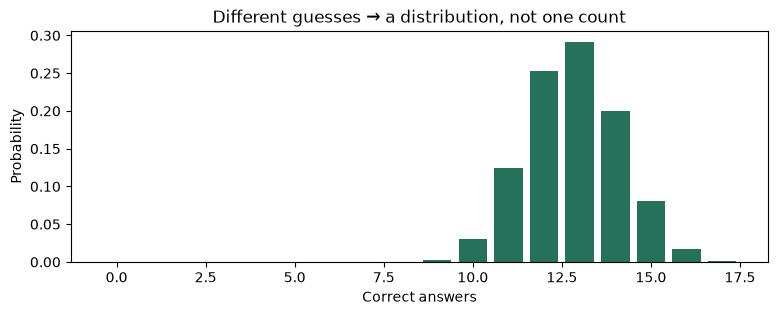

In [17]:
mixed = [0.99] * 10 + [0.5] * 4 + [1/3] * 2 + [0.25]
pmf = poisson_binomial(mixed)
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(pmf.keys(), pmf.values(), color="#26715a")
ax.set(xlabel="Correct answers", ylabel="Probability", title="Different guesses → a distribution, not one count")
plt.show()
assert abs(sum(pmf.values()) - 1) < 1e-10


## 3. Module inputs

I organize inputs by section and module: 27 questions per Reading & Writing module and 22 per Math module. Every question belongs to exactly one category.

- `confident`: believed correct, using a shared confidence probability.
- `guess2`, `guess3`, `guess4`: the number of choices remaining after elimination.
- `fill_right`, `fill_wrong`: Math responses verified against an answer key.
- `fill_uncertain`: Math responses assigned an explicit probability.
- `wrong`: other known wrong answers or unanswered questions.

I use 99% as the default probability for a confident answer. I haven't measured how well reported confidence matches correctness yet, so this is an assumption. A value of 1 would assume certainty.

The example below uses synthetic counts. I don't need to know which guesses were correct in order to calculate the possible outcomes.

In [18]:
# Synthetic example inputs; each module accounts for its full question count.
modules = {
    "rw": [
        Counts(confident=19, guess2=4, guess3=2, guess4=1, wrong=1),
        Counts(confident=16, guess2=5, guess3=3, guess4=2, wrong=1),
    ],
    "math": [
        Counts(confident=14, guess2=2, guess3=1, guess4=1,
               fill_right=2, fill_wrong=1, fill_uncertain=1),
        Counts(confident=12, guess2=3, guess3=1, guess4=1,
               fill_right=2, fill_wrong=1, fill_uncertain=1, wrong=1),
    ],
}
settings = Settings(confidence=0.99, fill_probability=0.25, coverage=0.90)
result = predict_test(**modules, settings=settings)
display(pd.DataFrame({name: data["raw_summary"] for name, data in result["sections"].items()}).T)
print("SAT score conversion:", result["score_status"])


,low,median,high,mean,variance,interval_mass
rw,38.0,42.0,45.0,41.566667,4.270111,0.94989
math,31.0,34.0,37.0,33.906667,2.701844,0.97073


SAT score conversion: not_calibrated


## 4. Interpreting low, median, and high

I define the quantile $q_\alpha=\min\{x:P(S\leq x)\geq\alpha\}$.
For a central 90% interval, I report $q_{.05}$, $q_{.50}$, and $q_{.95}$ as the likely low, median, and likely high outcomes.

These are quantiles rather than absolute minimum and maximum values. Because the distribution is discrete, the interval can contain more than 90% probability. It is a predictive interval conditional on the model, rather than a confidence interval for an unknown parameter.

Increasing the selected coverage cannot narrow this central interval, although the endpoints may stay fixed because answer counts are integers.

## 5. Pretest questions and Module 2 routing

Each module contains two unscored pretest questions. I approximate their unknown positions as a uniformly selected pair.
If $S=s$ of $n$ displayed questions are correct, and $U$ counts the correct answers in the pretest pair, then

$$P(U=u\mid S=s)=\frac{\binom{s}{u}\binom{n-s}{2-u}}{\binom{n}{2}}.$$

The numerator counts pairs containing $u$ correct and $2-u$ incorrect positions. The denominator counts all pairs. The resulting scored count is $s-u$.
Real pretest placement has restrictions, so uniform pairing is a simplifying assumption.

For an unknown Module 2 route, I use the illustrative function

$$P(H\mid s_1)=\operatorname{sigmoid}((s_1/n-t)/w).$$

Here $H$ denotes the harder route, $t$ is an assumed midpoint, and $w$ controls the transition width. This links routing to Module 1 performance. It is not College Board's routing algorithm or an established correct-answer threshold.

I sum over possible counts and routes using the law of total probability. An independently known route can instead be supplied as `hard` or `easy`.

## 6. Experimental SAT score conversion

The official SAT uses calibrated item characteristics. Counts alone do not recover that scoring process, so this conversion remains an **uncalibrated scenario model**.

I use the scored fraction $f=(s_1+s_2)/(2n)$ and the linear mapping

$$\text{base}=\text{floor}+(\text{cap}-\text{floor})f.$$

The easier route uses floor 200 and an assumed cap; the harder route uses an assumed floor and cap 800.
I add symmetric triangular noise in 10-point steps, round the result, and clip it to the route's limits. The default easier-route cap of 600 and the noise radius are illustrative parameters, not established SAT scoring facts.

I obtain the total distribution by convolving the two section distributions under assumed section independence, then calculate its quantiles. Adding section endpoint quantiles would not generally produce the same total interval.

The code requires `include_illustrative_scores=True` to make this conversion explicit.

,low,median,high,interval_mass
rw,480.0,650.0,710.0,0.927541
math,480.0,660.0,720.0,0.947601
total,1080.0,1290.0,1390.0,0.906909


Status: illustrative_only — not a calibrated SAT forecast


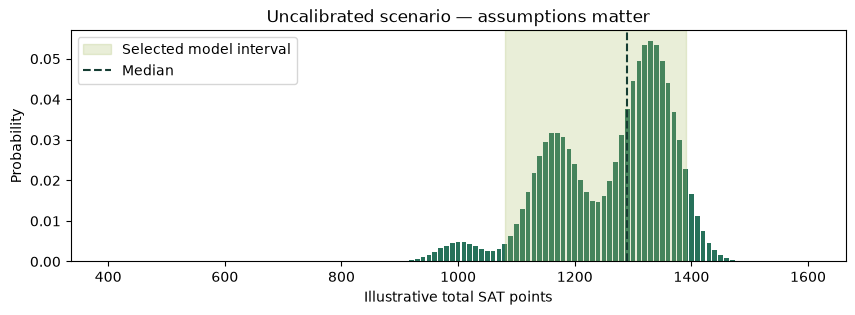

In [19]:
# Explicit opt-in to the uncalibrated SAT-point scenario.
routes = {"rw": "unknown", "math": "unknown"}  # or "hard" / "easy"
illustration = predict_test(**modules, routes=routes, settings=settings,
                            include_illustrative_scores=True)
rows = {name: data["score_summary"] for name, data in illustration["sections"].items()}
rows["total"] = illustration["total_score_summary"]
display(pd.DataFrame(rows).T[["low", "median", "high", "interval_mass"]])
print("Status:", illustration["score_status"], "— not a calibrated SAT forecast")

pmf = illustration["total_score_pmf"]
s = illustration["total_score_summary"]
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(pmf.keys(), pmf.values(), width=8, color="#26715a")
ax.axvspan(s["low"], s["high"], color="#a8be65", alpha=.25, label="Selected model interval")
ax.axvline(s["median"], color="#163d33", linestyle="--", label="Median")
ax.set(xlabel="Illustrative total SAT points", ylabel="Probability", title="Uncalibrated scenario — assumptions matter")
ax.legend()
plt.show()


## 7. Sensitivity to the assumed score cap

I compare easier-route caps of 550, 600, and 650 while holding the other settings fixed. This shows how an unverified conversion parameter affects the resulting interval.

This helps me see how much the range depends on a setting I haven't validated. A correct probability calculation doesn't make the score conversion accurate.

In [20]:
sensitivity = []
for cap in (550, 600, 650):
    r = predict_test(**modules, settings=replace(settings, easy_cap=cap),
                     include_illustrative_scores=True)
    sensitivity.append({"assumed_easy_cap": cap, **r["total_score_summary"]})
display(pd.DataFrame(sensitivity)[["assumed_easy_cap", "low", "median", "high"]])


,assumed_easy_cap,low,median,high
0,550,1040,1290,1390
1,600,1080,1290,1390
2,650,1130,1290,1390


## What I still need to test

The next notebook handles data storage and analysis. To evaluate the score model, I still need real practice-attempt inputs paired with actual scores. I would fit the conversion on one set of data and test it on separate students and test forms.

The main questions are how often the intervals contain the actual score, how wide they are, and how far the median prediction is from the actual result. I haven't measured those yet.